In [21]:

# Бібліотека для роботи з масивами
import numpy as np

# Бібліотека для побудови графіків
import matplotlib.pyplot as plt

# Набір рукописних цифр MNIST
from tensorflow.keras.datasets import mnist

# Бібліотека для створення нейромереж
from tensorflow import keras

# Шари згорткової нейромережі
from tensorflow.keras.layers import (
    Dense, Flatten, Conv2D, MaxPooling2D
)


In [22]:

# Завантажуємо набір даних MNIST
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Нормалізуємо значення пікселів від 0 до 1
x_train = x_train / 255.0
x_test = x_test / 255.0

# Додаємо розмірність каналу зображення
x_train = np.expand_dims(x_train, axis=3)
x_test = np.expand_dims(x_test, axis=3)

# Перетворюємо відповіді у вектори з 10 елементів
y_train_cat = keras.utils.to_categorical(y_train, 10)
y_test_cat = keras.utils.to_categorical(y_test, 10)

# Перевіряємо розмірність даних
print("Навчальні дані:", x_train.shape)
print("Тестові дані:", x_test.shape)


Навчальні дані: (60000, 28, 28, 1)
Тестові дані: (10000, 28, 28, 1)


In [23]:

# Створюємо згорткову нейронну мережу
model = keras.Sequential([

    # Вхідне зображення 28x28 з одним каналом
    keras.Input(shape=(28, 28, 1)),

    # Перший згортковий шар з 32 фільтрами
    Conv2D(32, (3, 3), padding='same', activation='relu'),

    # Зменшуємо розмір зображення вдвічі
    MaxPooling2D((2, 2), strides=2),

    # Другий згортковий шар з 64 фільтрами
    Conv2D(64, (3, 3), padding='same', activation='relu'),

    # Повторно зменшуємо розмір
    MaxPooling2D((2, 2), strides=2),

    # Перетворюємо дані в один вектор
    Flatten(),

    # Прихований шар зі 128 нейронами
    Dense(128, activation='relu'),

    # Вихідний шар для 10 цифр
    Dense(10, activation='softmax')
])

# Виводимо структуру моделі
model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:

# Налаштовуємо навчання нейромережі
model.compile(
    optimizer='adam',                # Оптимізатор
    loss='categorical_crossentropy', # Функція помилки
    metrics=['accuracy']             # Точність
)


In [25]:

# Навчаємо нейромережу протягом 7 епох
history = model.fit(
    x_train,
    y_train_cat,
    batch_size=32,          # Групи по 32 зображення
    epochs=7,              # 7 епох для 14 варіанта
    validation_split=0.2   # 20% для перевірки
)


Epoch 1/7
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 65s 42ms/step - accuracy: 0.9562 - loss: 0.1429 - val_accuracy: 0.9818 - val_loss: 0.0627
Epoch 2/7
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 61s 41ms/step - accuracy: 0.9848 - loss: 0.0466 - val_accuracy: 0.9849 - val_loss: 0.0512
Epoch 3/7
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 60s 40ms/step - accuracy: 0.9901 - loss: 0.0301 - val_accuracy: 0.9885 - val_loss: 0.0386
Epoch 4/7
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 62s 41ms/step - accuracy: 0.9925 - loss: 0.0226 - val_accuracy: 0.9873 - val_loss: 0.0433
Epoch 5/7
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 80s 40ms/step - accuracy: 0.9948 - loss: 0.0166 - val_accuracy: 0.9898 - val_loss: 0.0441
Epoch 6/7
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 61s 41ms/step - accuracy: 0.9956 - loss: 0.0131 - val_accuracy: 0.9891 - val_loss: 0.0400
Epoch 7/7
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 83s 41ms/step - accuracy: 0.9963 - loss: 0.0106 - val_accuracy: 0.9878 - val_loss: 0.0462


In [26]:

# Перевіряємо модель на тестових даних
loss, accuracy = model.evaluate(x_test, y_test_cat)

# Виводимо отриману точність
print("Точність:", round(accuracy * 100, 2), "%")

# Виводимо значення помилки
print("Помилка:", loss)


313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9892 - loss: 0.0340
Точність: 98.92 %
Помилка: 0.03402470424771309


Ймовірності: [[1.3356751e-12 1.5225942e-06 5.4739592e-14 2.2429009e-05 9.5658518e-13
  9.9997604e-01 1.4246909e-08 5.9129168e-10 1.6345373e-09 7.8591311e-09]]
Прогноз: 5
Правильна відповідь: 5


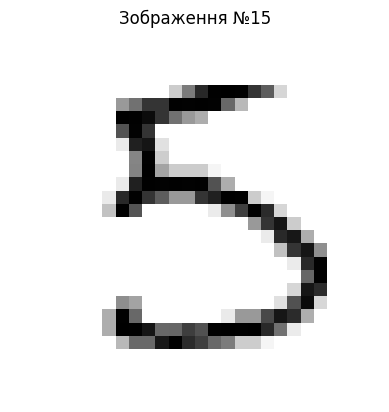

In [27]:

# Вибираємо зображення для 14 варіанта
n = 15

# Додаємо розмірність для одного зображення
x = np.expand_dims(x_test[n], axis=0)

# Отримуємо прогноз нейромережі
res = model.predict(x, verbose=0)

# Виводимо ймовірності для 10 цифр
print("Ймовірності:", res)

# Виводимо розпізнану цифру
print("Прогноз:", np.argmax(res))

# Виводимо правильну цифру
print("Правильна відповідь:", y_test[n])

# Показуємо саме зображення
plt.imshow(x_test[n].squeeze(), cmap=plt.cm.binary)
plt.title("Зображення №15")
plt.axis('off')
plt.show()


In [28]:

# Прогнозуємо всі тестові зображення
pred = model.predict(x_test)

# Визначаємо розпізнані цифри
pred = np.argmax(pred, axis=1)

# Виводимо кількість прогнозів
print(pred.shape)

# Перші 10 прогнозів
print("Прогнози:", pred[:10])

# Перші 10 правильних цифр
print("Правильні:", y_test[:10])


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step
(10000,)
Прогнози: [7 2 1 0 4 1 4 9 5 9]
Правильні: [7 2 1 0 4 1 4 9 5 9]


In [29]:

# Порівнюємо прогнози з правильними відповідями
mask = pred == y_test

# Виводимо результати порівняння
print(mask[:10])

# Вибираємо неправильно розпізнані зображення
x_false = x_test[~mask]

# Зберігаємо неправильні прогнози
p_false = pred[~mask]

# Зберігаємо правильні відповіді
y_false = y_test[~mask]

# Виводимо кількість помилок
print("Кількість помилок:", len(x_false))


[ True  True  True  True  True  True  True  True  True  True]
Кількість помилок: 108


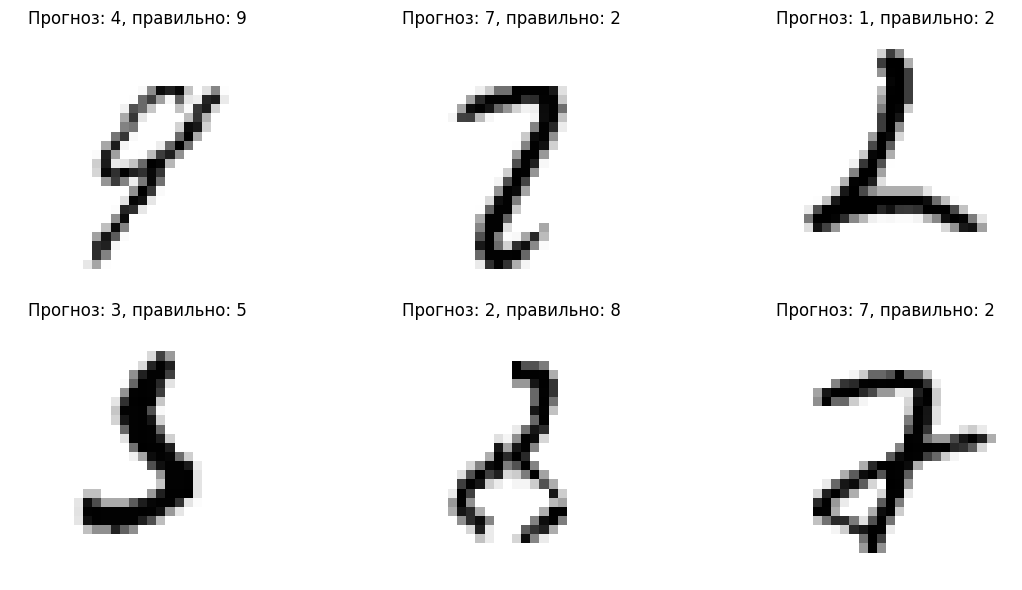

In [30]:

# Створюємо область для 6 зображень
plt.figure(figsize=(12, 6))

# Виводимо перші 6 помилок нейромережі
for i in range(min(6, len(x_false))):
    plt.subplot(2, 3, i + 1)

    # Показуємо неправильно розпізнану цифру
    plt.imshow(x_false[i].squeeze(), cmap=plt.cm.binary)

    # Порівнюємо прогноз із правильною цифрою
    plt.title(f"Прогноз: {p_false[i]}, правильно: {y_false[i]}")

    # Приховуємо осі
    plt.axis('off')

# Відображаємо зображення
plt.tight_layout()
plt.show()


**Висновок**

Під час виконання лабораторної роботи я ознайомилася з принципами роботи згорткових нейронних мереж та навчилася створювати їх за допомогою бібліотек TensorFlow і Keras у середовищі Google Colab.

Для розпізнавання рукописних цифр використала набір даних MNIST. Створила нейронну мережу з двома згортковими шарами Conv2D, двома шарами MaxPooling2D, шаром Flatten та повнозв'язними шарами Dense.

Відповідно до 14 варіанта передбачила навчання моделі протягом 7 епох, розпізнавання зображення з номером 15 та візуалізацію 6 неправильно розпізнаних зображень.

У результаті я закріпила навички створення, навчання та тестування згорткових нейронних мереж і аналізу помилок розпізнавання.